<a href="https://colab.research.google.com/github/wadeea23/ECG-Based-Heartbeat-Classification-Using-Machine-Learning/blob/main/ECG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [111]:
!pip install wfdb

In [112]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [113]:
import zipfile

zip_path = '/content/drive/MyDrive/GA/Capstone_GA/mitdb-1.0.0.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/mitdb-1.0.0')

In [114]:
import wfdb
import os
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split , GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, MaxPooling1D, Flatten
from sklearn.preprocessing import StandardScaler

In [115]:
folder = '/content/mitdb-1.0.0/mit-bih-arrhythmia-database-1.0.0'

print(os.listdir(folder)[:20])

['123.dat', '228.xws', 'ANNOTATORS', '108.atr', 'RECORDS', '111.atr', '234.atr', '208.hea', '202.atr', 'x_mitdb', '106.hea', '200.atr', '103.xws', '202.xws', '102.dat', '113.atr', '219.hea', '105.atr', '215.hea', '101.xws']


In [116]:
files = os.listdir(folder)

dat_count = str(files).count('.dat')
hea_count = str(files).count('.hea')
atr_count = str(files).count('.atr')

print("DAT:", dat_count)
print("HEA:", hea_count)
print("ATR:", atr_count)

DAT: 48
HEA: 48
ATR: 49


In [117]:
# convert all clissy to aami in all records
N = all_labels['N'] + all_labels['L'] + all_labels['R'] + all_labels['e'] + all_labels['j']

S = all_labels['A'] + all_labels['a'] + all_labels['J'] + all_labels['S']

V = all_labels['V'] + all_labels['E']

F = all_labels['F']

Q = all_labels['/'] + all_labels['f'] + all_labels['Q']

print("N:", N)
print("S:", S)
print("V:", V)
print("F:", F)
print("Q:", Q)

N: 90631
S: 2781
V: 7236
F: 803
Q: 8043


In [118]:
signal = record.p_signal[:, 0] #MLII CHANNEL I choose first channel to my model

print("Signal Shape:", signal.shape)
print("Sampling Rate:", record.fs)

Signal Shape: (650000,)
Sampling Rate: 360


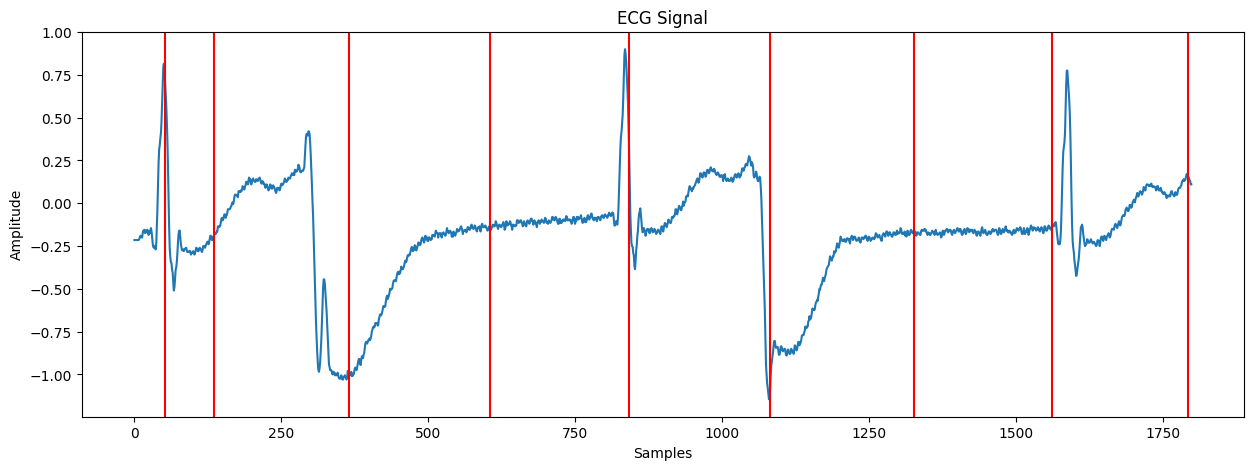

In [119]:
plt.figure(figsize=(15, 5))

plt.plot(signal[:1800]) # i choose 1800 / 360 hz = 5 sec

for peak in annotation.sample:
    if peak < 1800:
        plt.axvline(peak, color='red') # يحدد مكان النبض بالخطوط الطولية

plt.title('ECG Signal')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

In [120]:
# Heartbeat to prepare the data to train models

In [121]:
# i will prapare the data to 48 record

In [122]:
X = []
y = []
for file in os.listdir(folder):

    if '.hea' in file:

        name = file.replace('.hea', '')

        record = wfdb.rdrecord(folder + '/' + name)
        labels = wfdb.rdann(folder + '/' + name, 'atr')

        signal = record.p_signal[:, 0]

        for i in range(len(labels.sample)):

            peak = labels.sample[i]
            label = labels.symbol[i]

            if label in ['N', 'L', 'R', 'e', 'j']:
                label = 'N'

            elif label in ['A', 'a', 'J', 'S']:
                label = 'S'

            elif label in ['V', 'E']:
                label = 'V'

            elif label != 'F':
                continue

            if peak >= 120 and peak + 240 <= len(signal):

                beat = signal[peak-120:peak+240]

                X.append(beat)
                y.append(label)

X = np.array(X)
y = np.array(y)

X = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 0.00000001)

print(X.shape)
print(Counter(y))

(101396, 360)
Counter({np.str_('N'): 90579, np.str_('V'): 7235, np.str_('S'): 2780, np.str_('F'): 802})


In [123]:
# model 1 split the data

In [124]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42,stratify=y_train)

In [125]:
# model 1 binary classify 0=normal / 1=abnormal

In [126]:
y_train_binary = (y_train != 'N').astype(int) # to convert n to 0 other to 1
y_val_binary = (y_val != 'N').astype(int)
y_test_binary = (y_test != 'N').astype(int)

In [127]:
# model 2 to classfy abnormal

In [128]:
X_train_2 = X_train[y_train != 'N'] # remove all normal
y_train_2 = y_train[y_train != 'N']

X_val_2 = X_val[y_val != 'N']
y_val_2 = y_val[y_val != 'N']

X_test_2 = X_test[y_test != 'N']
y_test_2 = y_test[y_test != 'N']

In [129]:
## dt for bainary model

In [130]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train_binary)

pred = dt_model.predict(X_val)

print(classification_report(y_val_binary, pred))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98     14493
           1       0.86      0.88      0.87      1731

    accuracy                           0.97     16224
   macro avg       0.92      0.93      0.93     16224
weighted avg       0.97      0.97      0.97     16224



In [131]:
pred = dt_model.predict(X_test)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99     18117
           1       0.88      0.88      0.88      2163

    accuracy                           0.97     20280
   macro avg       0.93      0.93      0.93     20280
weighted avg       0.97      0.97      0.97     20280



In [132]:
# knn model

In [133]:
scaler = StandardScaler()   # preprocessing
X_train_scaler = scaler.fit_transform(X_train)
X_val_scaler = scaler.transform(X_val)
X_test_scaler = scaler.transform(X_test)

In [134]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaler, y_train_binary)

knn_pred = knn_model.predict(X_val_scaler)

print(classification_report(y_val_binary, knn_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99     14493
           1       0.95      0.92      0.93      1731

    accuracy                           0.99     16224
   macro avg       0.97      0.96      0.96     16224
weighted avg       0.99      0.99      0.99     16224



In [135]:
pred = knn_model.predict(X_test_scaler)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18117
           1       0.96      0.91      0.93      2163

    accuracy                           0.99     20280
   macro avg       0.98      0.95      0.96     20280
weighted avg       0.99      0.99      0.99     20280



In [136]:
# cnn model

In [137]:
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val_cnn = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

cnn_model = Sequential([
    Conv1D(32, 3, activation='relu', input_shape=(360, 1)),
    MaxPooling1D(2),
    Conv1D(64, 3, activation='relu'),
    MaxPooling1D(2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [138]:
cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [ ]:
cnn_model.fit(X_train_cnn, y_train_binary, epochs=10, validation_data=(X_val_cnn, y_val_binary))


Epoch 1/10
2028/2028 ━━━━━━━━━━━━━━━━━━━━ 55s 26ms/step - accuracy: 0.9707 - loss: 0.0964 - val_accuracy: 0.9809 - val_loss: 0.0659
Epoch 2/10
2028/2028 ━━━━━━━━━━━━━━━━━━━━ 55s 27ms/step - accuracy: 0.9837 - loss: 0.0530 - val_accuracy: 0.9874 - val_loss: 0.0437
Epoch 3/10
2028/2028 ━━━━━━━━━━━━━━━━━━━━ 51s 25ms/step - accuracy: 0.9877 - loss: 0.0404 - val_accuracy: 0.9888 - val_loss: 0.0387
Epoch 4/10
 430/2028 ━━━━━━━━━━━━━━━━━━━━ 34s 22ms/step - accuracy: 0.9928 - loss: 0.0242

In [ ]:
pred = (cnn_model.predict(X_val_cnn) > 0.5).astype(int)

print(classification_report(y_val_binary, pred))

In [ ]:
cnn_pred = cnn_model.predict(X_test_cnn)

cnn_pred = (pred > 0.5).astype(int)

print(classification_report(y_test_binary, cnn_pred))